# Parte 2 – Mapas del Perú

Responsable: Cristian Wong

**Pasos 1 a 3 del issue:** enlazar nuestros datos con las geometrías oficiales de los departamentos y dibujar coropletas estáticas con GeoPandas.


In [1]:
import pandas as pd
import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap



## Paso 1. Unir ubigeo de 2 dígitos con el nombre del departamento

Para unir una tabla con un mapa hace falta una columna escrita **exactamente igual** en los dos lados. Nuestra tabla trae dos candidatas: `ubigeo` (código del INEI de 2 dígitos) y `departamento` (nombre). El ubigeo se lee como texto con `dtype={"ubigeo": str}`.

In [2]:
datos = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (25, 9)


,ubigeo,departamento,declaratorias,prorrogas,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte
0,01,Amazonas,1,0,Chachapoyas,-6.23169,-77.86903,436.5,1
1,02,Áncash,0,0,Huaraz,-9.52614,-77.52869,975.3,7
2,03,Apurímac,0,0,Abancay,-13.63426,-72.88380,711.8,2
3,04,Arequipa,0,0,Arequipa,-16.39899,-71.53747,189.9,0
4,05,Ayacucho,1,0,Ayacucho,-13.16380,-74.22345,485.1,0


La tabla tiene 25 filas, una por departamento, y 9 columnas. El ubigeo aparece como `01`, `02`, ... con el cero de la izquierda.

In [3]:
sin_dtype = pd.read_csv("datos/dataset.csv")
print("Sin dtype    :", sin_dtype["ubigeo"].head(3).tolist(), "| tipo:", sin_dtype["ubigeo"].dtype)
print("Con dtype=str:", datos["ubigeo"].head(3).tolist(), "| tipo:", datos["ubigeo"].dtype)
print("¿Los 25 ubigeos tienen 2 caracteres?", (datos["ubigeo"].str.len() == 2).all())

Sin dtype    : [1, 2, 3] | tipo: int64
Con dtype=str: ['01', '02', '03'] | tipo: str
¿Los 25 ubigeos tienen 2 caracteres? True


Sin `dtype`, pandas cree que `01` es un número y lo guarda como `1`: el cero desaparece y ese código ya no coincide con `"01"`. Con `dtype={"ubigeo": str}` se conserva el texto tal cual, y los 25 códigos tienen sus 2 caracteres. Por eso, en todo el notebook el ubigeo se trata como texto.

### El nombre, escrito como en las geometrías oficiales

Las geometrías oficiales escriben el departamento en mayúsculas y sin tildes (`ANCASH`, `SAN MARTIN`); lo comprobamos en el paso 2. Creamos la columna `nombre_mapa` con ese mismo formato: pasamos a mayúsculas y cambiamos cada vocal con tilde por la misma vocal sin tilde.

In [4]:
sin_tildes = {"Á": "A", "É": "E", "Í": "I", "Ó": "O", "Ú": "U"}
datos["nombre_mapa"] = datos["departamento"].str.upper().replace(sin_tildes, regex=True)

# Los nombres con tilde son los únicos que pasar a mayúsculas no basta para arreglar
datos.loc[datos["departamento"].str.upper() != datos["nombre_mapa"], ["ubigeo", "departamento", "nombre_mapa"]]

,ubigeo,departamento,nombre_mapa
1,02,Áncash,ANCASH
2,03,Apurímac,APURIMAC
9,10,Huánuco,HUANUCO
11,12,Junín,JUNIN
21,22,San Martín,SAN MARTIN


`.str.upper()` pasa todo a mayúsculas y `.replace(sin_tildes, regex=True)` cambia las letras **dentro** del texto (sin `regex=True` solo reemplazaría celdas completas). Solo 5 nombres cambian de forma: Áncash, Apurímac, Huánuco, Junín y San Martín. Ya tenemos las dos llaves listas: `ubigeo` como texto de 2 dígitos y `nombre_mapa`.

## Paso 2. Cargar el GeoJSON y unirlo con los datos

In [5]:
departamentos = gpd.read_file("datos/departamentos_peru.geojson")
print("Filas y columnas:", departamentos.shape)
print("Sistema de coordenadas:", departamentos.crs)
departamentos.head()

Filas y columnas: (25, 2)
Sistema de coordenadas: EPSG:4326


,departamento,geometry
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838..."
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32..."
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5..."
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6..."
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1..."


Son 25 geometrías, una por departamento, en `EPSG:4326` (latitud y longitud en grados, como el GPS). El archivo solo trae dos columnas: `departamento`, en mayúsculas y sin tildes, y `geometry`, la frontera de cada uno. **No trae ubigeo**, así que el primer enlace tiene que hacerse por el nombre.

In [6]:
solo_mayusculas = datos["departamento"].str.upper()
print("Coinciden solo con mayúsculas       :", solo_mayusculas.isin(departamentos["departamento"]).sum(), "de", len(datos))
print("No coinciden:", datos.loc[~solo_mayusculas.isin(departamentos["departamento"]), "departamento"].tolist())
print("Coinciden con mayúsculas y sin tilde:", datos["nombre_mapa"].isin(departamentos["departamento"]).sum(), "de", len(datos))

Coinciden solo con mayúsculas       : 20 de 25
No coinciden: ['Áncash', 'Apurímac', 'Huánuco', 'Junín', 'San Martín']
Coinciden con mayúsculas y sin tilde: 25 de 25


`.isin()` revisa, fila por fila, si el nombre aparece en el GeoJSON, y `~` lo invierte para listar los que **no** aparecen. Con solo mayúsculas, 5 departamentos no cruzarían y saldrían en blanco en el mapa. Con `nombre_mapa` coinciden los 25.

In [7]:
# Mismo nombre de columna en las dos tablas, para que el merge sea directo
departamentos = departamentos.rename(columns={"departamento": "nombre_mapa"})
departamentos = departamentos.merge(datos[["nombre_mapa", "ubigeo"]], on="nombre_mapa", how="left", validate="one_to_one")

print("Geometrías sin ubigeo:", departamentos["ubigeo"].isna().sum())
departamentos[["nombre_mapa", "ubigeo"]].head()

Geometrías sin ubigeo: 0


,nombre_mapa,ubigeo
0,AMAZONAS,01
1,ANCASH,02
2,APURIMAC,03
3,AREQUIPA,04
4,AYACUCHO,05


El nombre solo sirve para que cada geometría reciba su código de ubigeo. Desde aquí el cruce con los datos se hace **por ubigeo**, que no depende de tildes ni mayúsculas, y es la misma llave que usará el mapa interactivo (`key_on="feature.properties.ubigeo"`). `validate="one_to_one"` detiene el merge con un error si algún nombre estuviera repetido, en vez de duplicar polígonos sin avisar. Las 25 geometrías ya tienen su ubigeo.

### Verificar antes de cruzar

In [8]:
print("Mapa  :", departamentos["ubigeo"].dtype, "| ejemplo:", departamentos["ubigeo"].iloc[0])
print("Tabla :", datos["ubigeo"].dtype, "| ejemplo:", datos["ubigeo"].iloc[0])
print("Coinciden:", len(set(departamentos["ubigeo"]) & set(datos["ubigeo"])), "de", len(datos))

Mapa  : str | ejemplo: 01
Tabla : str | ejemplo: 01
Coinciden: 25 de 25


En los dos lados el ubigeo es texto (`object`) y empieza con cero (`01`). `set(a) & set(b)` deja los códigos que están en ambas tablas: coinciden los 25.

In [9]:
datos_sin_geometria = datos[~datos["ubigeo"].isin(departamentos["ubigeo"])]
geometrias_sin_datos = departamentos[~departamentos["ubigeo"].isin(datos["ubigeo"])]

print("Departamentos de la tabla sin geometría:", len(datos_sin_geometria), datos_sin_geometria["departamento"].tolist())
print("Geometrías sin datos en la tabla       :", len(geometrias_sin_datos), geometrias_sin_datos["nombre_mapa"].tolist())

Departamentos de la tabla sin geometría: 0 []
Geometrías sin datos en la tabla       : 0 []


**Registros que no cruzaron: ninguno.** Revisamos las dos direcciones: departamentos de la tabla que no encuentran su geometría y geometrías que no encuentran sus datos. Si alguno fallara, aquí aparecería su nombre. El único problema real estaba en el nombre: sin quitar las tildes, Áncash, Apurímac, Huánuco, Junín y San Martín se habrían quedado fuera.

In [10]:
mapa = departamentos.merge(datos.drop(columns="nombre_mapa"), on="ubigeo", how="left", validate="one_to_one")
print(type(mapa))
mapa[["ubigeo", "departamento", "declaratorias", "lluvia_total_mm", "dias_lluvia_fuerte"]].head()

<class 'geopandas.geodataframe.GeoDataFrame'>


,ubigeo,departamento,declaratorias,lluvia_total_mm,dias_lluvia_fuerte
0,01,Amazonas,1,436.5,1
1,02,Áncash,0,975.3,7
2,03,Apurímac,0,711.8,2
3,04,Arequipa,0,189.9,0
4,05,Ayacucho,1,485.1,0


El merge se hace **desde el mapa** con `how="left"`, para que ninguna geometría se pierda: si un departamento no tuviera datos, quedaría con `NaN` y saldría sin color. No lo rellenaríamos con 0, porque eso sería inventar que no llovió. Quitamos `nombre_mapa` de la tabla porque el mapa ya tiene esa columna. Como la tabla de la izquierda es un GeoDataFrame, el resultado también lo es: tiene los datos y las formas juntos.

In [11]:
print("Filas             -> mapa:", len(mapa), "| tabla:", len(datos))
print("Declaratorias     -> mapa:", mapa["declaratorias"].sum(), "| tabla:", datos["declaratorias"].sum())
print("Lluvia total (mm) -> mapa:", round(mapa["lluvia_total_mm"].sum(), 1), "| tabla:", round(datos["lluvia_total_mm"].sum(), 1))
print("Departamentos sin dato de lluvia en el mapa:", mapa["lluvia_total_mm"].isna().sum())

Filas             -> mapa: 25 | tabla: 25
Declaratorias     -> mapa: 3 | tabla: 3
Lluvia total (mm) -> mapa: 13290.2 | tabla: 13290.2
Departamentos sin dato de lluvia en el mapa: 0


Las filas, las declaratorias y la lluvia suman lo mismo en el mapa que en la tabla, y ningún departamento quedó sin dato. El cruce no perdió ni duplicó nada.

## Paso 3. Mapa estático con GeoPandas

### Antes de dibujar: cerrar rendijas del archivo

El GeoJSON trae más de mil huecos diminutos (rendijas de menos de 0.2 km²). GeoPandas dibuja el borde de cada uno, y dentro de Junín forman una línea blanca que parece una frontera que no existe. Para el dibujo las cerramos.

In [12]:
# En UTM zona 18 sur las distancias están en metros; en grados no se puede pedir "150 m"
mapa_en_metros = mapa.to_crs(32718)
area_antes = mapa_en_metros.area

# Agrandar 150 m y volver a achicar 150 m cierra las rendijas de menos de 300 m de ancho
mapa_en_metros["geometry"] = mapa_en_metros.buffer(150).buffer(-150)
cambio_area = (mapa_en_metros.area / area_antes - 1) * 100
print("Cambio máximo de área en un departamento:", round(cambio_area.abs().max(), 2), "%")

mapa = mapa_en_metros.to_crs(4326)

Cambio máximo de área en un departamento: 0.09 %


`.to_crs(32718)` pasa las coordenadas a metros. `.buffer(150)` agranda cada departamento 150 m hacia afuera, lo que tapa las rendijas, y `.buffer(-150)` lo devuelve a su tamaño. Los contornos quedan prácticamente iguales, las lagunas grandes que sí son huecos reales (como Parinacochas en Ayacucho o Arapa en Puno) se mantienen, y el área de cada departamento cambia menos de 0.1 %. Al final volvemos a grados con `.to_crs(4326)`. Esto solo cambia el dibujo; los datos no se tocan.

### Nombres sobre el mapa

La función permite rotular departamentos destacados sin depender solo del color.

In [13]:
def rotular(ax, mapa, nombres):
    # Fondo blanco para que el texto se lea también sobre los azules oscuros
    for _, fila in mapa[mapa["departamento"].isin(nombres)].iterrows():
        punto = fila["geometry"].representative_point()
        ax.annotate(fila["departamento"], xy=(punto.x, punto.y), ha="center", va="center", fontsize=8,
                    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.85})


fuente_lluvia = ("Fuente: Open-Meteo, API histórica (lluvia diaria en la capital de cada departamento, "
                 "1 ene–31 may 2022).\nLímites: departamentos_peru.geojson (sesión 7 del curso).")

`rotular` recorre los departamentos de la lista y escribe su nombre en `representative_point()`, un punto que siempre cae dentro del polígono (el centroide puede caer fuera en formas irregulares). `fuente_lluvia` guarda el texto de la fuente que comparten los dos mapas de lluvia.

### Mapa 1. Lluvia total, por cuantiles

Con `scheme="quantiles"` y `k=5`, GeoPandas ordena los 25 departamentos de menor a mayor y los reparte en 5 grupos de 5, uno por color. Así los colores no se amontonan: con intervalos iguales, el valor extremo de Loreto (1582 mm) dejaría 9 departamentos en el tono más claro y solo 1 y 2 en los dos más oscuros. Primero miramos los cortes.


In [14]:
mapclassify.Quantiles(mapa["lluvia_total_mm"], k=5)

Quantiles

     Interval        Count
--------------------------
[  11.50,   79.20] |     5
(  79.20,  394.82] |     5
( 394.82,  736.40] |     5
( 736.40,  824.64] |     5
( 824.64, 1581.80] |     5

Cada grupo tiene 5 departamentos. `(79.20, 394.82]` se lee "más de 79.2 mm y hasta 394.8 mm". Los cortes no son el valor de ningún departamento: mapclassify los calcula entre dos vecinos (79.2 cae entre Callao, con 39.2 mm, y Piura, con 89.2 mm). En el grupo más seco ningún departamento pasa de 40 mm, y en el más lluvioso todos superan los 900 mm. En la leyenda del mapa los cortes aparecen redondeados: 79, 395, 736 y 825.


In [15]:
from matplotlib.patches import Rectangle

# Cinco tonos de un mismo azul: claro = poca lluvia, oscuro = mucha
azules_5 = ListedColormap(["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])

PROFESOR = "Alexander Quispe Rojas"
EQUIPO = "Equipo Nº 13"
FUENTE = ("Fuente: Open-Meteo, API histórica. Lluvia diaria en la capital de cada "
          "departamento, 1 ene–31 may 2022.")
logo_pucp = plt.imread("imagenes/logo_pucp.png")

# La escala solo es real en metros; en grados un km mide distinto según la latitud
mapa_utm = mapa.to_crs(32718)


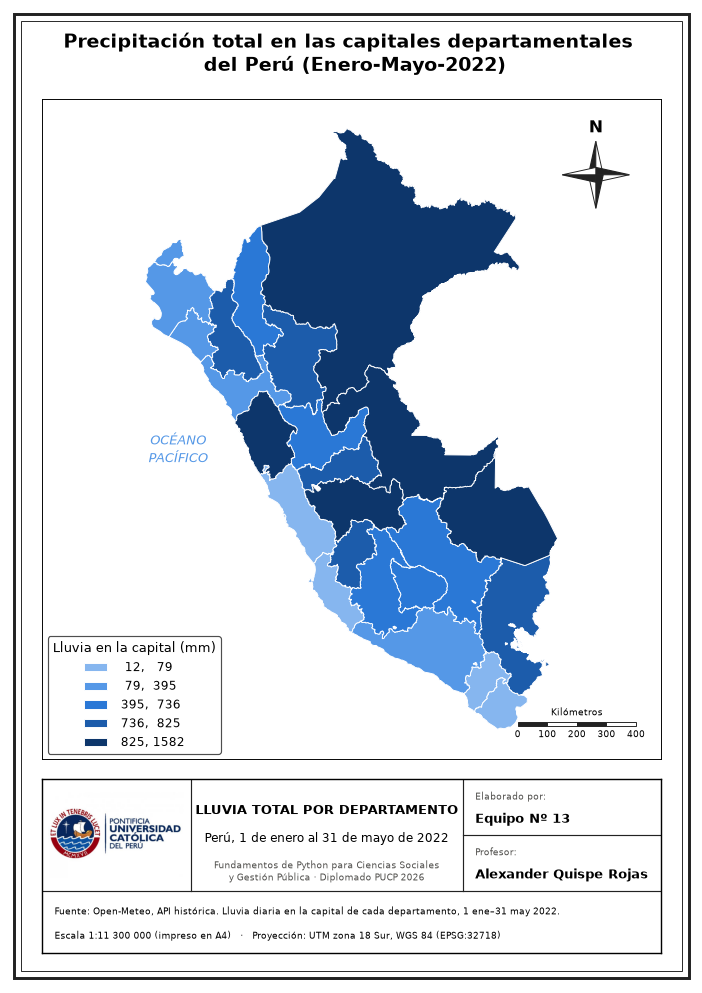

In [16]:
# Tamaño A4 vertical: la escala numérica del cajetín vale al imprimir en A4
fig = plt.figure(figsize=(8.27, 11.69))

# Marco doble alrededor de toda la lámina
fig.add_artist(Rectangle((0.02, 0.015), 0.96, 0.97, transform=fig.transFigure, fill=False, linewidth=2.5, edgecolor="#222222"))
fig.add_artist(Rectangle((0.03, 0.022), 0.94, 0.956, transform=fig.transFigure, fill=False, linewidth=0.8, edgecolor="#222222"))

# Título centrado y más grande
fig.text(0.5, 0.945, "Precipitación total en las capitales departamentales \n del Perú (Enero-Mayo-2022)",
         ha="center", va="center", fontsize=16, fontweight="bold")

# Mapa: la caja del mapa queda fija y el Perú se centra dentro de ella
ax = fig.add_axes([0.06, 0.235, 0.88, 0.665])
mapa_utm.plot(column="lluvia_total_mm", scheme="quantiles", k=5, cmap=azules_5,
              edgecolor="white", linewidth=0.8, legend=True, ax=ax,
              legend_kwds={"title": "Lluvia en la capital (mm)", "loc": "lower left", "fmt": "{:.0f}",
                           "fontsize": 10, "title_fontsize": 11, "frameon": True, "edgecolor": "#222222"})

ax.set_aspect("equal", adjustable="datalim")
ax.apply_aspect()   # fija ya los límites finales, que la escala gráfica necesita
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.text(0.22, 0.45, "OCÉANO\nPACÍFICO", transform=ax.transAxes, ha="center", fontsize=11,
        style="italic", color="#5598e7")

# Brújula (rosa de los vientos): cada punta tiene una mitad oscura y otra clara
brujula = ax.inset_axes([0.83, 0.82, 0.13, 0.15])
brujula.set_xlim(-1.2, 1.2)
brujula.set_ylim(-1.2, 1.6)
brujula.set_aspect("equal")
brujula.axis("off")
for x, y in [(0, 1), (1, 0), (0, -1), (-1, 0)]:
    ancho_x, ancho_y = -y * 0.22, x * 0.22
    brujula.fill([0, x, ancho_x], [0, y, ancho_y], color="#222222")
    brujula.fill([0, x, -ancho_x], [0, y, -ancho_y], facecolor="white", edgecolor="#222222", linewidth=0.8)
brujula.text(0, 1.15, "N", ha="center", va="bottom", fontsize=14, fontweight="bold")

# Escala gráfica de 400 km en tramos de 100 km, abajo a la derecha del mapa
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
inicio_x = x_max - (x_max - x_min) * 0.04 - 400_000
inicio_y = y_min + (y_max - y_min) * 0.05
for tramo in range(4):
    color = "#222222" if tramo % 2 == 0 else "white"
    ax.add_patch(Rectangle((inicio_x + tramo * 100_000, inicio_y), 100_000, 15_000,
                           facecolor=color, edgecolor="#222222", linewidth=0.8))
    ax.text(inicio_x + tramo * 100_000, inicio_y - 12_000, str(tramo * 100), ha="center", va="top", fontsize=8)
ax.text(inicio_x + 400_000, inicio_y - 12_000, "400", ha="center", va="top", fontsize=8)
ax.text(inicio_x + 200_000, inicio_y + 30_000, "Kilómetros", ha="center", va="bottom", fontsize=8)

# Escala numérica: metros del mapa entre metros del papel, redondeada a cientos de miles
ancho_papel_m = ax.get_window_extent().width / fig.dpi * 0.0254
escala = round((x_max - x_min) / ancho_papel_m, -5)
escala_texto = f"{escala:,.0f}".replace(",", " ")   # 11 300 000, con espacios como se escribe en español

# Cajetín: líneas que lo dividen en casillas
cajetin = fig.add_axes([0.06, 0.04, 0.88, 0.175])
cajetin.set_xlim(0, 1)
cajetin.set_ylim(0, 1)
cajetin.set_xticks([])
cajetin.set_yticks([])
for borde in cajetin.spines.values():
    borde.set_linewidth(1.2)
cajetin.axhline(0.36, color="#222222", linewidth=1)
cajetin.plot([0.24, 0.24], [0.36, 1], color="#222222", linewidth=1)
cajetin.plot([0.68, 0.68], [0.36, 1], color="#222222", linewidth=1)
cajetin.plot([0.68, 1], [0.68, 0.68], color="#222222", linewidth=1)

logo = cajetin.inset_axes([0.01, 0.39, 0.22, 0.58])
logo.imshow(logo_pucp)
logo.axis("off")

cajetin.text(0.46, 0.82, "LLUVIA TOTAL POR DEPARTAMENTO", ha="center", va="center", fontsize=11, fontweight="bold")
cajetin.text(0.46, 0.66, "Perú, 1 de enero al 31 de mayo de 2022", ha="center", va="center", fontsize=10)
cajetin.text(0.46, 0.47, "Fundamentos de Python para Ciencias Sociales\ny Gestión Pública · Diplomado PUCP 2026",
             ha="center", va="center", fontsize=8, color="#52514e")
cajetin.text(0.70, 0.90, "Elaborado por:", va="center", fontsize=8, color="#52514e")
cajetin.text(0.70, 0.77, EQUIPO, va="center", fontsize=11, fontweight="bold")
cajetin.text(0.70, 0.58, "Profesor:", va="center", fontsize=8, color="#52514e")
cajetin.text(0.70, 0.45, PROFESOR, va="center", fontsize=11, fontweight="bold")
cajetin.text(0.02, 0.24, FUENTE, va="center", fontsize=8)
cajetin.text(0.02, 0.10, f"Escala 1:{escala_texto} (impreso en A4)   ·   Proyección: UTM zona 18 Sur, WGS 84 (EPSG:32718)",
             va="center", fontsize=8)

plt.show()


### Mapa 2. Días de lluvia fuerte, por cuantiles

Este mapa complementa el acumulado de lluvia mostrando la frecuencia de días de lluvia fuerte en las capitales. Se usan tres grupos por cuantiles porque hay muchos valores repetidos, especialmente ceros. Los valores representan las capitales, no toda la superficie departamental.

Quantiles

   Interval      Count
----------------------
[ 0.00,  0.00] |    10
( 0.00,  2.00] |     7
( 2.00, 25.00] |     8


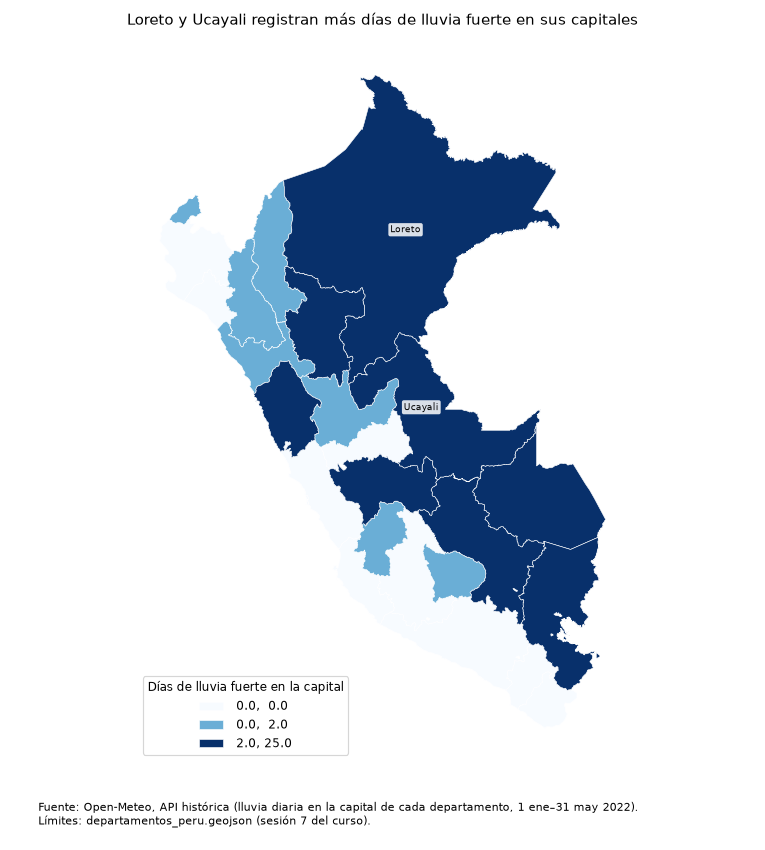

In [17]:
clasificacion = mapclassify.Quantiles(mapa["dias_lluvia_fuerte"], k=3)
print(clasificacion)

fig, ax = plt.subplots(figsize=(9, 10))
mapa.plot(
    column="dias_lluvia_fuerte", scheme="quantiles", k=3,
    cmap="Blues", edgecolor="white", linewidth=0.5,
    legend=True, ax=ax,
    legend_kwds={"title": "Días de lluvia fuerte en la capital",
                 "loc": "lower left", "fmt": "{:.1f}"}
)
rotular(ax, mapa, ["Loreto", "Ucayali"])
ax.set_title("Loreto y Ucayali registran más días de lluvia fuerte en sus capitales",
             fontsize=13, pad=15)
ax.set_axis_off()
fig.text(0.05, 0.03, fuente_lluvia, fontsize=9)
plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()